# 01. Data Understanding, Cleaning and EDA

**Goal of this notebook:** understand the dunnhumby *Breakfast at the Frat* panel well enough to make three downstream
decisions correctly:

1. how to **forecast** weekly demand (what grain, which features, which traps),
2. whether the data can identify **price elasticity** (does price vary, and why does it vary?),
3. which **limitations** (stockouts, missing cost) must be carried into the optimization.

Every observation below is written as *what we see → why it matters → what it changes in the modelling*.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from src import config
R = config.RESULTS_DIR
%matplotlib inline

## 1. Load the raw data
The workbook has a transaction sheet plus store and product lookups (`src/data_loader.py`).

In [2]:
from src import data_loader, preprocessing as pp
tx, stores, products = data_loader.load_raw()
print("transactions:", tx.shape, "| stores lookup:", stores.shape, "| products lookup:", products.shape)
tx.head()

transactions: (524950, 12) | stores lookup: (79, 9) | products lookup: (58, 6)


,week_end_date,store_num,upc,units,visits,hhs,spend,price,base_price,feature,display,tpr_only
0,2009-01-14,367,1111009477,13,13,13,18.0700,1.3900,1.5700,0,0,1
1,2009-01-14,367,1111009497,20,18,18,27.8000,1.3900,1.3900,0,0,0
2,2009-01-14,367,1111009507,14,14,14,19.3200,1.3800,1.3800,0,0,0
3,2009-01-14,367,1111035398,4,3,3,14.0000,3.5000,4.4900,0,0,1
4,2009-01-14,367,1111038078,3,3,3,7.5000,2.5000,2.5000,0,0,0


## 2. Column meaning, types, missing values, duplicates
| column | meaning |
|---|---|
| `week_end_date` | week ending date (weeks end on Wednesday) |
| `store_num`, `upc` | store id, product id |
| `units` | units sold (**target**) |
| `visits`, `hhs` | baskets and households containing the product (**outcomes of the same week → leakage, never used as features**) |
| `spend` | dollar sales |
| `price` | actual average shelf price paid |
| `base_price` | regular (non-promoted) price |
| `feature`, `display`, `tpr_only` | circular ad, in-store display, temporary price reduction without ad/display |

In [3]:
info = pd.DataFrame({"dtype": tx.dtypes.astype(str), "missing": tx.isna().sum(), "missing_%": tx.isna().mean() * 100,
                     "n_unique": tx.nunique()})
print("duplicate (week, store, upc) keys:", tx.duplicated(["week_end_date", "store_num", "upc"]).sum())
info

duplicate (week, store, upc) keys: 0


,dtype,missing,missing_%,n_unique
week_end_date,datetime64[us],0,0.0000,156
store_num,int64,0,0.0000,77
upc,int64,0,0.0000,55
units,int64,0,0.0000,568
visits,int64,0,0.0000,456
hhs,int64,0,0.0000,446
spend,float64,0,0.0000,20287
price,float64,23,0.0044,699
base_price,float64,185,0.0352,676
feature,int64,0,0.0000,2


**Is `SPEND = PRICE × UNITS`?** If yes, a missing price can be recovered from spend and units, and we learn that
`price` is the average price actually paid in that store-week.

In [4]:
d = tx[(tx.units > 0) & tx.price.notna()]
print("max |spend - price*units| =", float((d.spend - d.price * d.units).abs().max()))
print("rows with units == 0:", int((tx.units == 0).sum()), "| rows with missing price:", int(tx.price.isna().sum()))
tx[tx.units == 0]

max |spend - price*units| = 0.0
rows with units == 0: 5 | rows with missing price: 23


,week_end_date,store_num,upc,units,visits,hhs,spend,price,base_price,feature,display,tpr_only
66221,2009-06-10,6187,31254742835,0,2,2,0.0000,NaN,4.9900,0,0,0
150740,2009-12-02,28909,31254742735,0,2,2,0.0000,NaN,4.9900,0,0,0
152090,2009-12-09,11967,31254742735,0,2,1,0.0000,NaN,4.7900,0,0,0
181398,2010-02-10,389,3700019521,0,2,2,0.0000,NaN,3.4900,0,0,0
373945,2011-03-02,19521,3000006610,0,6,5,0.0000,NaN,2.9800,0,0,0


**Observation.** The identity holds exactly, so `price` is the realised average price. The handful of rows with
`units == 0` have no price and zero spend, although `visits > 0`. They look like voids or returns, not "zero demand".

**Observation (store lookup).** Two stores appear twice in the lookup with different segments:

In [5]:
stores[stores.store_id.duplicated(keep=False)]

,store_id,store_name,address_city_name,address_state_prov_code,msa_code,seg_value_name,parking_space_qty,sales_area_size_num,avg_weekly_baskets
22,4503,ROCKWALL,ROCKWALL,TX,19100,MAINSTREAM,NaN,56230,"25,289.3269"
39,17627,FLOWER MOUND,FLOWER MOUND,TX,19100,MAINSTREAM,513.0000,59213,"18,196.8205"
54,17627,FLOWER MOUND,FLOWER MOUND,TX,19100,UPSCALE,513.0000,59213,"18,196.8205"
61,4503,ROCKWALL,ROCKWALL,TX,19100,UPSCALE,NaN,56230,"25,289.3269"


A naive join would silently **duplicate** every transaction of those stores (13,693 rows). The cleaning step
keeps the first listing and logs the decision.

## 3. Cleaning (`src/preprocessing.py`)
Principle: *never delete silently*. Every step is logged with a reason.

In [6]:
panel, log = pp.clean_transactions(tx, stores, products)
log

,step,rows_affected,action,reason
0,raw rows,524950,none,starting point
1,"duplicate (week, store, upc)",0,drop,the panel key must be unique; none were found
2,"missing/zero price, units>0",0,impute price = spend/units,accounting identity SPEND = PRICE*UNITS holds ...
3,units == 0 (with visits > 0),5,drop,no price recorded and no units; likely voided ...
4,price still missing,19,drop,price not recoverable
5,missing base_price,185,ffill/bfill within store-product,regular price changes rarely; neighbouring wee...
6,price > base_price,4937,set base_price = price (flagged),base price is the regular (non-discounted) pri...
7,extreme units (> median + 10*IQR within store-...,1734,flag only (kept),"may be genuine events (promotions, holidays) o..."
8,store lookup: same store_id listed twice with ...,13693,keep first listing (MAINSTREAM); rows kept,"stores [4503, 17627] appear twice; a naive joi..."
9,rows without store attributes,0,keep,store lookup joined; missing values would be l...


Key decisions:
* **Missing base price** is filled forward/backward within the store-product, because regular prices are sticky.
* **Price above base price** (≈1% of rows) is inconsistent by definition. The base price is raised to the shelf price and the row is flagged.
* **Outliers are flagged, not removed.** A 10×-normal week is often a real promotion or Super Bowl spike. Deleting it would
  delete exactly the variation that identifies promotion effects. Notebook 03 re-estimates elasticities without them as a robustness check.

## 4. The stockout / zero-sales problem
The data has **no rows for store-product-weeks without sales**. So we cannot tell apart:
true zero demand · out-of-stock · product not ranged in that store · data gap.

In [7]:
cov = pp.coverage_table(panel)
print(f"store-product-weeks present: {len(panel):,} of {cov.possible_rows.sum():,} possible "
      f"({len(panel) / cov.possible_rows.sum():.1%})")
cov.head(10)

store-product-weeks present: 524,926 of 609,804 possible (86.1%)


,upc,description,stores,rows,possible_rows,coverage
24,3500068914,COLG SPEARMINT WISP,73,1399,11388,0.1228
17,2066200532,NWMN OWN SUPREME PIZZA,45,2755,7020,0.3925
16,2066200531,NWMN OWN 4 CHEESE PIZZA,59,3807,9204,0.4136
15,2066200530,NWMN OWN PEPPERONI PIZZA,67,5106,10452,0.4885
33,4116709565,ACT RSTR CL SPLSH MINT MW,76,7218,11856,0.6088
31,4116709428,ACT MINT A/CAV FLUOR RNS,76,7230,11856,0.6098
32,4116709448,ACT KIDS BBLGUM FLUOR RNS,76,7651,11856,0.6453
45,7218063983,FRSC 4 CHEESE PIZZA,75,8710,11700,0.7444
25,3700019521,CREST PH WHTG CLN MINT TP,76,8947,11856,0.7546
18,2840002333,RLDGLD BRAIDED HONEY WHT,75,9262,11700,0.7916


**Why it matters / what we do:**
* In forecasting we build a complete weekly calendar and leave missing weeks as **NaN, not 0**. Treating them as 0 would teach the model
  that demand collapses whenever a product was merely unavailable. We add a feature `weeks_observed_last_13` so the model can learn availability patterns.
* We evaluate only weeks with recorded sales, so the forecast answers "*how much will sell, given it sells*".
* In elasticity, `log(units)` exists only for positive sales. Any week where a high price drove sales to exactly zero is missing. That is a
  **selection bias**, documented as a limitation. It probably makes estimated elasticities slightly *less* negative than the truth.

## 5. Size of the problem

In [8]:
print("weeks:", panel.week.nunique(), "|", panel.week.min().date(), "->", panel.week.max().date())
print("stores:", panel.store_num.nunique(), "| products:", panel.upc.nunique())
display(panel.groupby("category").agg(products=("upc", "nunique"), rows=("units", "size"), total_units=("units", "sum"),
                                      mean_price=("price", "mean")))
display(panel.groupby("store_segment").store_num.nunique().rename("stores"))

weeks: 156 | 2009-01-14 -> 2012-01-04
stores: 77 | products: 55


,products,rows,total_units,mean_price
category,,,,
BAG SNACKS,15,127459,2601453,2.2006
COLD CEREAL,15,169687,5827381,2.7397
FROZEN PIZZA,12,111264,1343288,5.3143
ORAL HYGIENE PRODUCTS,13,116516,521210,3.7655


store_segment
MAINSTREAM    43
UPSCALE       15
VALUE         19
Name: stores, dtype: int64

## 6. Distributions of units, price and discounts

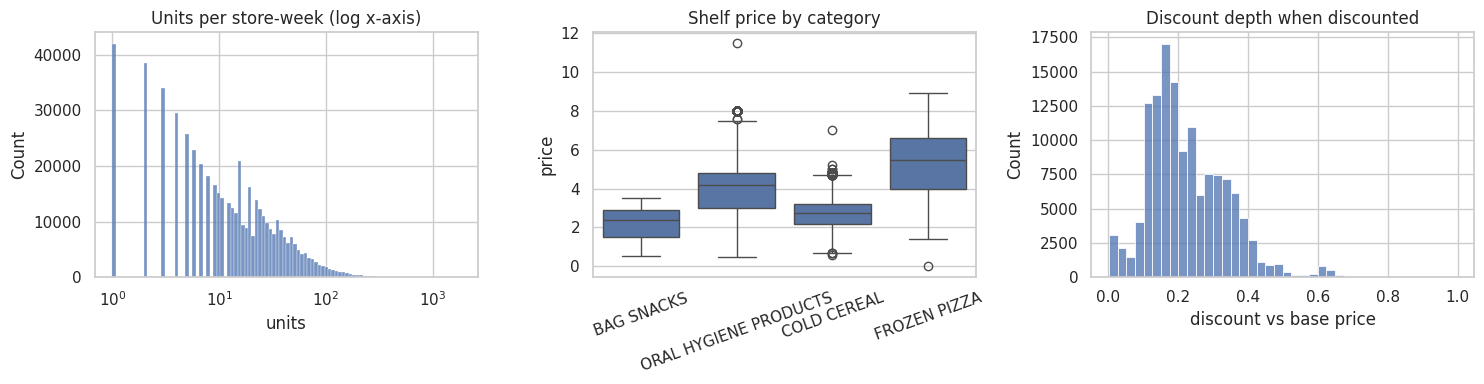

,units,price,base_price,discount_pct
count,"524,926.0000","524,926.0000","524,926.0000","524,926.0000"
mean,19.6091,3.3822,3.6043,0.0578
std,29.9346,1.5593,1.6316,0.1136
min,1.0000,0.0100,0.5500,0.0000
1%,1.0000,0.9800,1.1900,0.0000
25%,4.0000,2.3600,2.5000,0.0000
50%,10.0000,2.9900,3.1800,0.0000
75%,24.0000,4.4900,4.5900,0.0347
99%,138.0000,7.4900,7.4900,0.4286
max,"1,800.0000",11.4600,11.4600,0.9969


In [9]:
from src import visualization as viz
viz.distributions(panel, name=None); plt.show()
panel[["units", "price", "base_price", "discount_pct"]].describe(percentiles=[.01, .25, .5, .75, .99])

**Observation.** Units are heavily right-skewed (median ≈10, max 1,800).
**Why it matters:** squared-error models on raw units are dominated by a few huge store-weeks, and MAPE explodes on 1-2 unit weeks.
**Modelling:** train on `log1p(units)` and report **WMAPE**. For elasticity, use `log(units)`, which is exactly the log-log specification.

## 7. Trends and seasonality

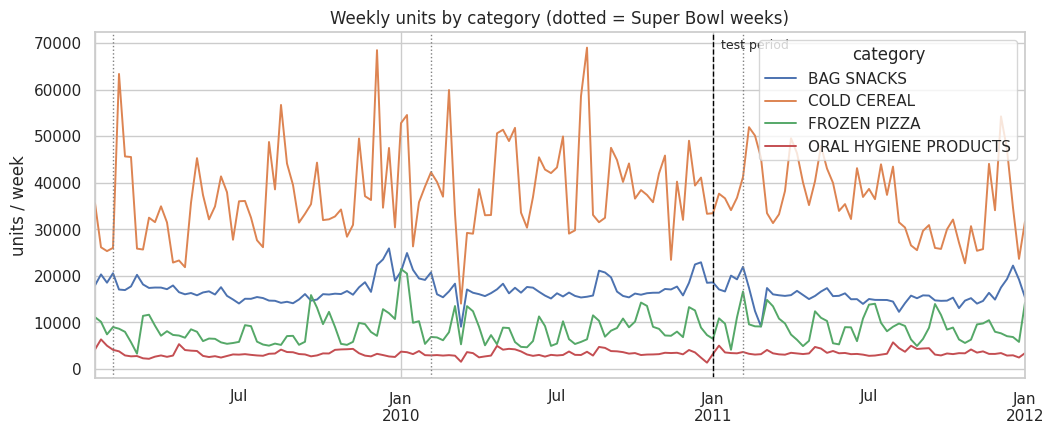

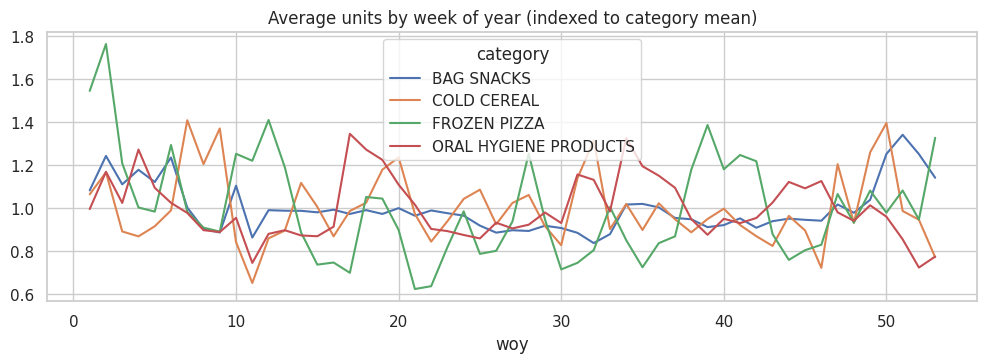

In [10]:
viz.weekly_units_by_category(panel, name=None); plt.show()
woy = panel.assign(woy=panel.week.dt.isocalendar().week.astype(int)).groupby(["category", "woy"]).units.mean().unstack(0)
(woy / woy.mean()).plot(figsize=(12, 3.5), title="Average units by week of year (indexed to category mean)"); plt.show()

**Observation.** Weekly totals are spiky rather than smoothly seasonal. The big spikes come from promotion weeks and events
(e.g. Super Bowl for pretzels and frozen pizza), not from a clean yearly curve.
**Why it matters:** a *seasonal-naive* forecast (same week last year) will be weak, because last year's promotion calendar is not this
year's. **Modelling:** we still include calendar and holiday features and the lag-52 feature, but we expect price and promotion features to carry most of the signal.

## 8. Promotions: how often and how strong?

share of store-weeks discounted: 25.7%, featured: 8.4%, on display: 11.0%


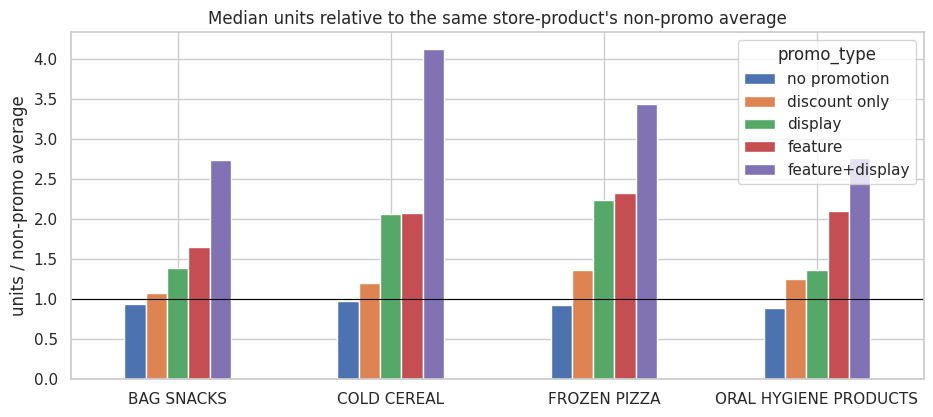

promo_type,no promotion,discount only,display,feature,feature+display
category,,,,,
BAG SNACKS,0.9429,1.0764,1.3822,1.6500,2.7393
COLD CEREAL,0.9771,1.1959,2.0617,2.0709,4.1335
FROZEN PIZZA,0.9184,1.3643,2.2354,2.3292,3.4422
ORAL HYGIENE PRODUCTS,0.8925,1.2453,1.3619,2.0962,2.7596


In [11]:
print(f"share of store-weeks discounted: {panel.on_discount.mean():.1%}, featured: {panel.feature.mean():.1%}, "
      f"on display: {panel.display.mean():.1%}")
fig, lift = viz.promo_lift(panel, name=None); plt.show()
lift

**Observation.** Relative to the same store-product's non-promoted average, units rise strongly with display and even more with feature
advertising. The discount alone gives a smaller lift.
**Why it matters (central to this project):** promotions change price **and** visibility at the same time. If we regress units on price
without controlling for feature/display, the ad and display effect is wrongly attributed to price, and the elasticity looks far too negative.
**Modelling:** feature and display are controls in every controlled elasticity model.

## 9. Price during vs outside promotions

In [12]:
g = panel.groupby(["category", "any_promo"]).agg(mean_price=("price", "mean"), mean_units=("units", "mean"),
                                                 mean_discount=("discount_pct", "mean")).unstack()
g

mean_price        mean_units         mean_discount       
any_promo                      0      1          0       1             0      1
category                                                                       
BAG SNACKS                2.3313 1.9012    16.7981 28.6818        0.0000 0.1516
COLD CEREAL               2.8985 2.2283    25.5011 62.8039        0.0000 0.2102
FROZEN PIZZA              5.6021 4.6634     7.9034 21.5023        0.0000 0.2141
ORAL HYGIENE PRODUCTS     4.0684 3.0965     3.5171  6.5851        0.0000 0.2400

## 10. Demand vs price, and the confounding trap
The raw price-quantity cloud mixes different stores, weeks and products. Here is one product with the raw slope,
and the slope after removing store and week means (fixed effects, explained in notebook 03).

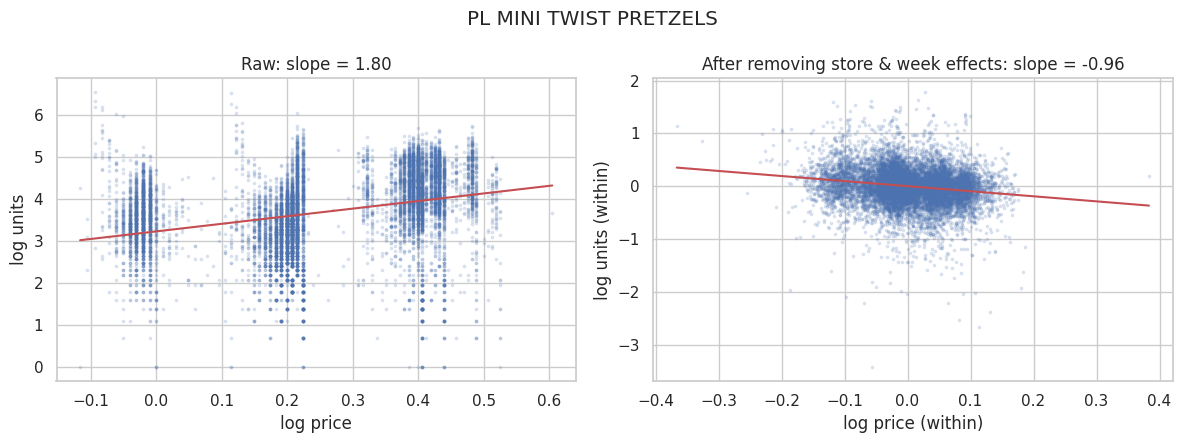

,spec,M1 naive,M4 + store FE + week FE
upc,description,,
1111009477,PL MINI TWIST PRETZELS,1.8013,-0.8018
1111009497,PL PRETZEL STICKS,1.2393,-0.8492
1111009507,PL TWIST PRETZELS,1.8904,-0.8861
1111085319,PL HONEY NUT TOASTD OATS,0.2362,-0.2740


In [13]:
ladder = pd.read_csv(R / "elasticity_ladder.csv")
wide = ladder.pivot_table(index=["upc", "description"], columns="spec", values="elasticity")
flip = wide[(wide["M1 naive"] > 0) & (wide["M4 + store FE + week FE"] < 0)]
example = flip.index[0][0]
viz.confounding_scatter(panel, example, name=None); plt.show()
flip[["M1 naive", "M4 + store FE + week FE"]]

**Observation.** For these private-label products the raw slope is **positive**, which would imply "raise the price, sell more". After
comparing each store only with itself and each week only with itself, the slope becomes negative.
**Why:** stores that charge more for private label are also bigger or busier stores (a store effect), and prices move in weeks when demand
moves (a time effect). This is confounding, and it is the single most important lesson of the EDA.

## 11. Top and low-volume products

In [14]:
vol = panel.groupby(["upc", "description", "category"]).agg(units=("units", "sum"), rows=("units", "size"),
                                                           mean_units=("units", "mean")).sort_values("units", ascending=False)
display(vol.head(8)); display(vol.tail(8))

,,,units,rows,mean_units
upc,description,category,,,
1600027527,GM HONEY NUT CHEERIOS,COLD CEREAL,804228,11985,67.1029
1111009477,PL MINI TWIST PRETZELS,BAG SNACKS,670625,11938,56.1757
3800031838,KELL FROSTED FLAKES,COLD CEREAL,565894,11980,47.2366
1111009497,PL PRETZEL STICKS,BAG SNACKS,531011,11960,44.3989
1600027564,GM CHEERIOS,COLD CEREAL,517126,11980,43.1658
1111085350,PL BT SZ FRSTD SHRD WHT,COLD CEREAL,468195,11963,39.1369
3800039118,KELL FROOT LOOPS,COLD CEREAL,458639,11948,38.3863
3800031829,KELL BITE SIZE MINI WHEAT,COLD CEREAL,396439,11904,33.3030


,,,units,rows,mean_units
upc,description,category,,,
7110410470,MKSL DUTCH PRETZELS,BAG SNACKS,29769,4542,6.5542
2066200531,NWMN OWN 4 CHEESE PIZZA,FROZEN PIZZA,25599,3807,6.7242
7110410471,MKSL PRETZEL STICKS,BAG SNACKS,23437,4450,5.2667
4116709448,ACT KIDS BBLGUM FLUOR RNS,ORAL HYGIENE PRODUCTS,18045,7651,2.3585
4116709428,ACT MINT A/CAV FLUOR RNS,ORAL HYGIENE PRODUCTS,16389,7230,2.2668
4116709565,ACT RSTR CL SPLSH MINT MW,ORAL HYGIENE PRODUCTS,15226,7218,2.1094
2066200532,NWMN OWN SUPREME PIZZA,FROZEN PIZZA,13668,2755,4.9612
3500068914,COLG SPEARMINT WISP,ORAL HYGIENE PRODUCTS,1833,1399,1.3102


**Observation.** The low-volume products (e.g. Colgate Wisp, Newman's Own pizzas, some Mike-sell's pretzels) sell in fewer stores and
fewer weeks. **Why it matters:** fewer observations give noisier elasticities. **Modelling:** notebook 03 enforces minimum-data rules and
uses empirical-Bayes shrinkage, so noisy product estimates borrow strength from their category.

## 12. Summary of EDA decisions
| Finding | Consequence |
|---|---|
| SPEND = PRICE × UNITS exactly | price is recoverable; `price` = realised average price |
| Duplicate stores in lookup | deduplicate before join (logged) |
| No rows for zero-sales weeks | NaN not 0; availability feature; selection-bias limitation |
| Skewed units | log1p target, WMAPE metric |
| Spiky, promotion-driven demand | price/promo features are key; seasonal-naive will be weak |
| Promotions bundle price + ad + display | control for feature/display in elasticity |
| Raw price-demand slopes can have the wrong sign | fixed effects are necessary |
| No cost data | profit only under an explicit ASSUMED margin |